# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown

def plot_ticker(ticker, method='DQN'):
    """Plot candlestick chart with buy/sell arrows for a given ticker and method."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]  # Capitalize for mplfinance
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    # The CSV has unadjusted OHLC but an Adjusted_Close column.
    # The agent trades at adjusted prices, so we must adjust the
    # candlestick data to match.
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Extract BUY and SELL trades ---
    buys = trades_df[trades_df['action'] == 'BUY'].copy()
    sells = trades_df[trades_df['action'] == 'SELL'].copy()
    
    # Create marker series aligned to stock_df index
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    # For each buy trade, find the nearest stock data date and place price marker
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        # Find nearest date in stock_df
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Calculate performance stats ---
    initial_val = trades_df['portfolio_value'].iloc[0]
    final_val = trades_df['portfolio_value'].iloc[-1]
    total_return = (final_val - initial_val) / initial_val * 100
    n_buys = len(buys)
    n_sells = len(sells)
    
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {total_return:+.1f}%  |  '
             f'Final: ${final_val:,.0f}  |  '
             f'Buys: {n_buys}  |  Sells: {n_sells}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 9),
        tight_layout=True, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend manually
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    plt.show()

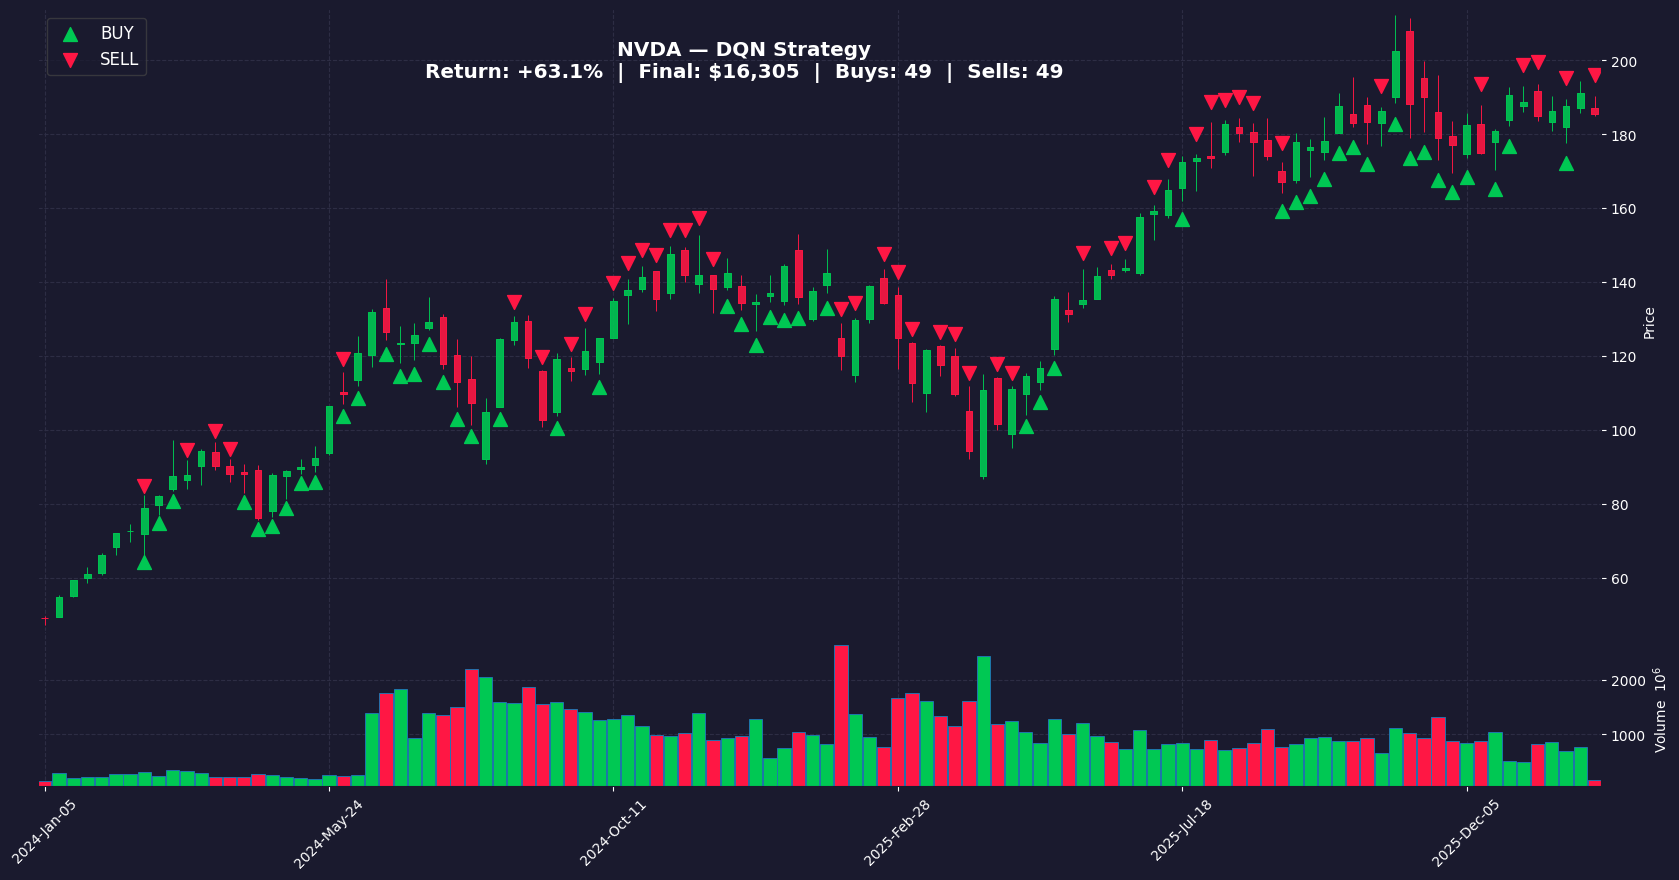

In [60]:
plot_ticker('NVDA', method='DQN')

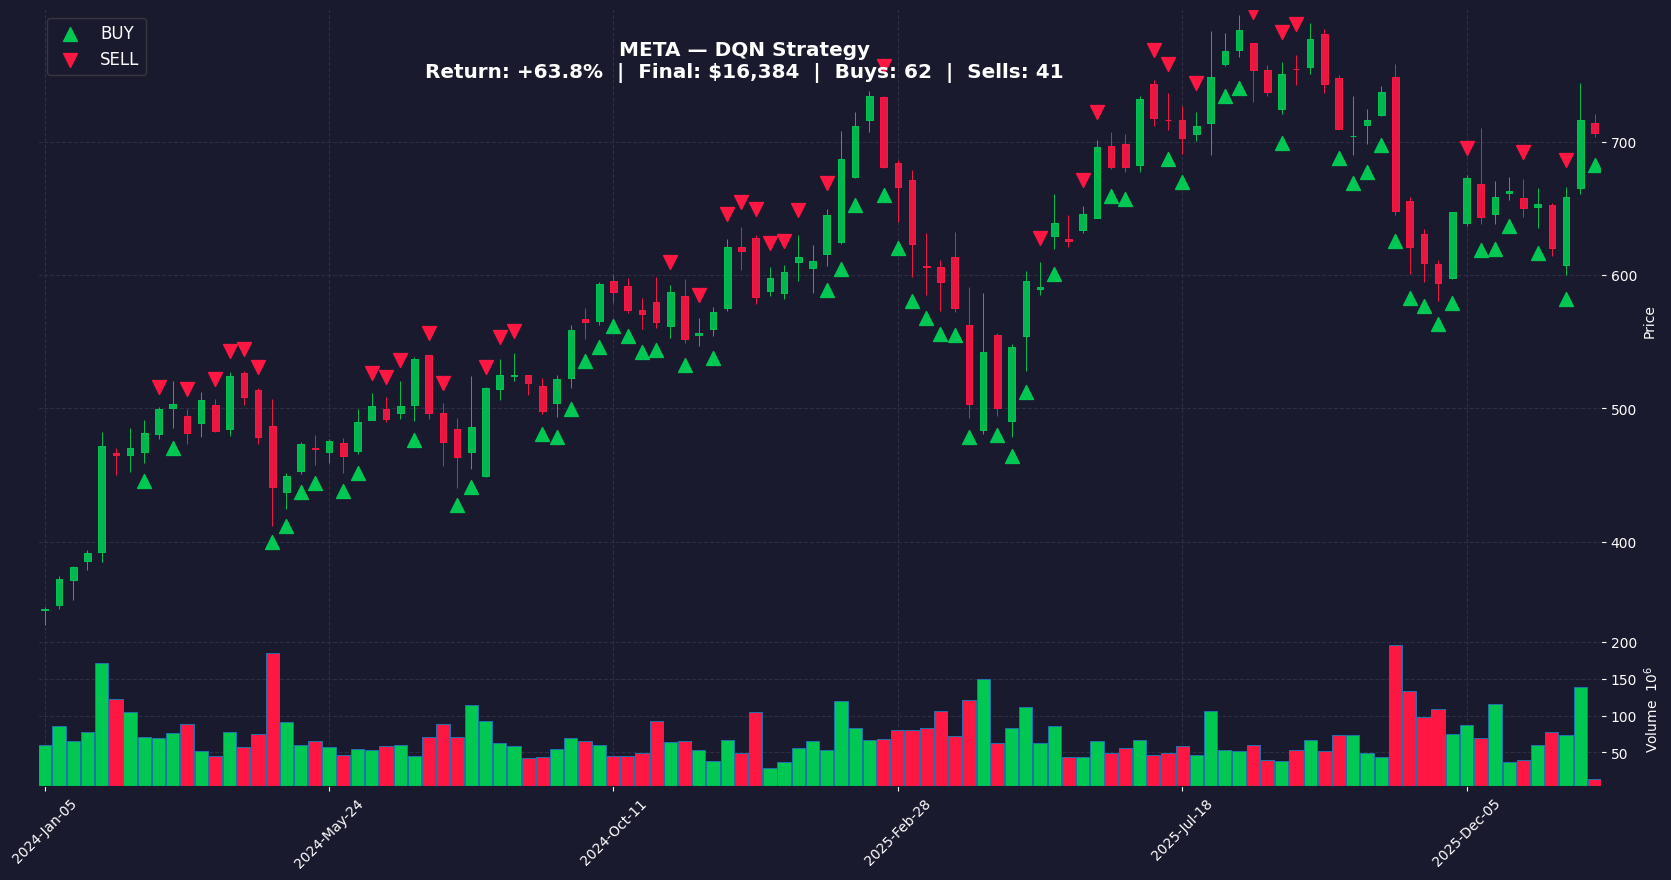

In [61]:
plot_ticker('META', method='DQN')

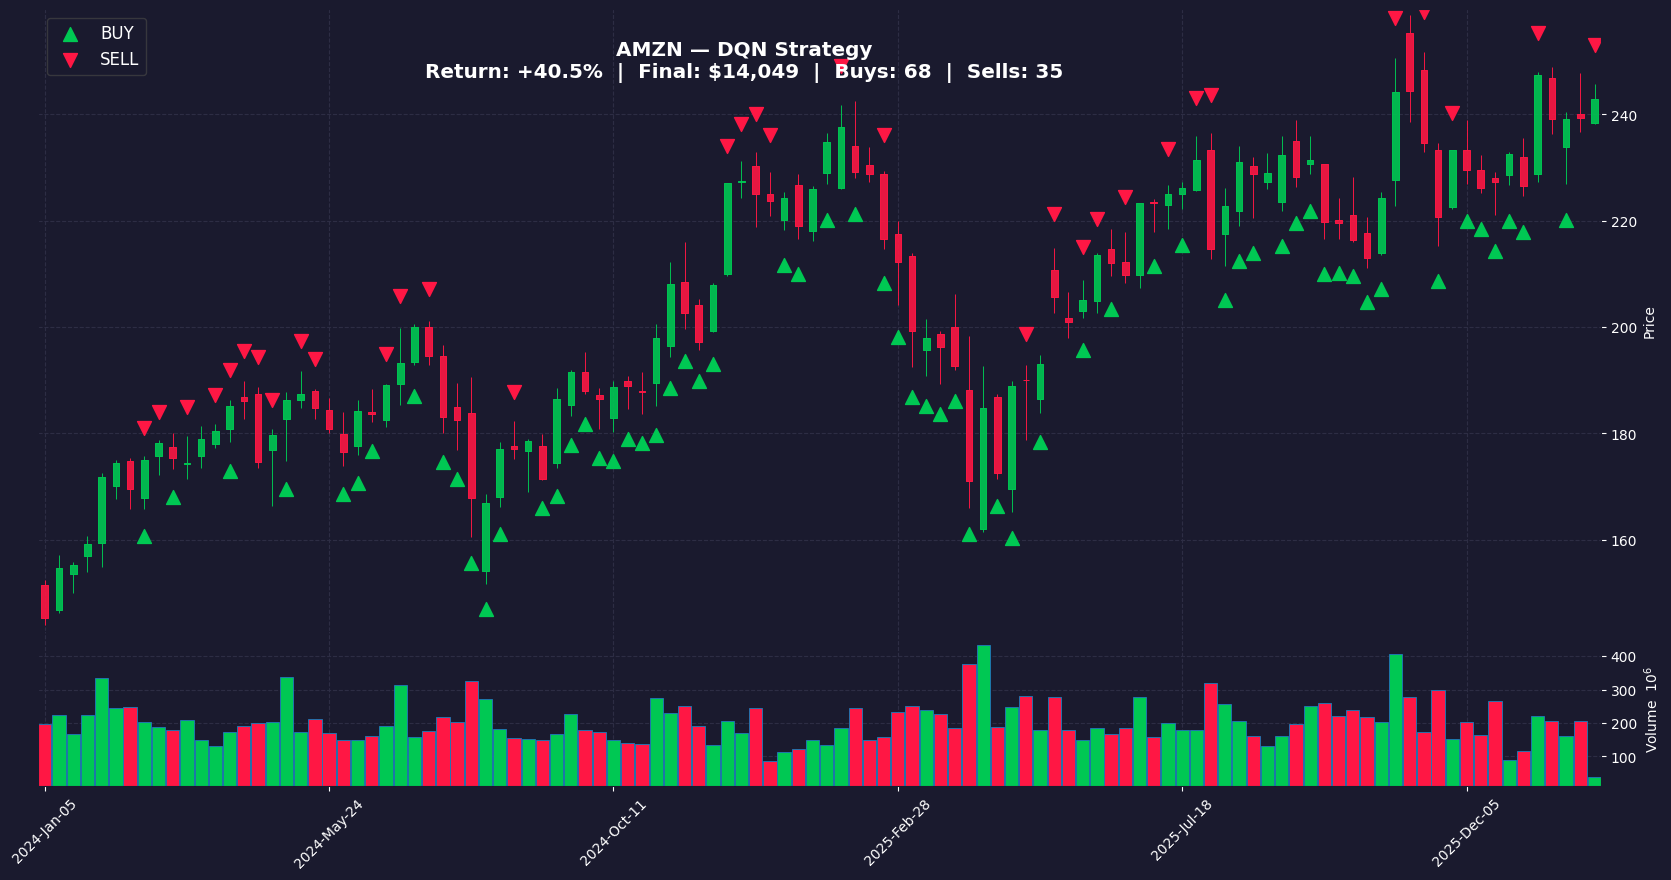

In [62]:
plot_ticker('AMZN', method='DQN')

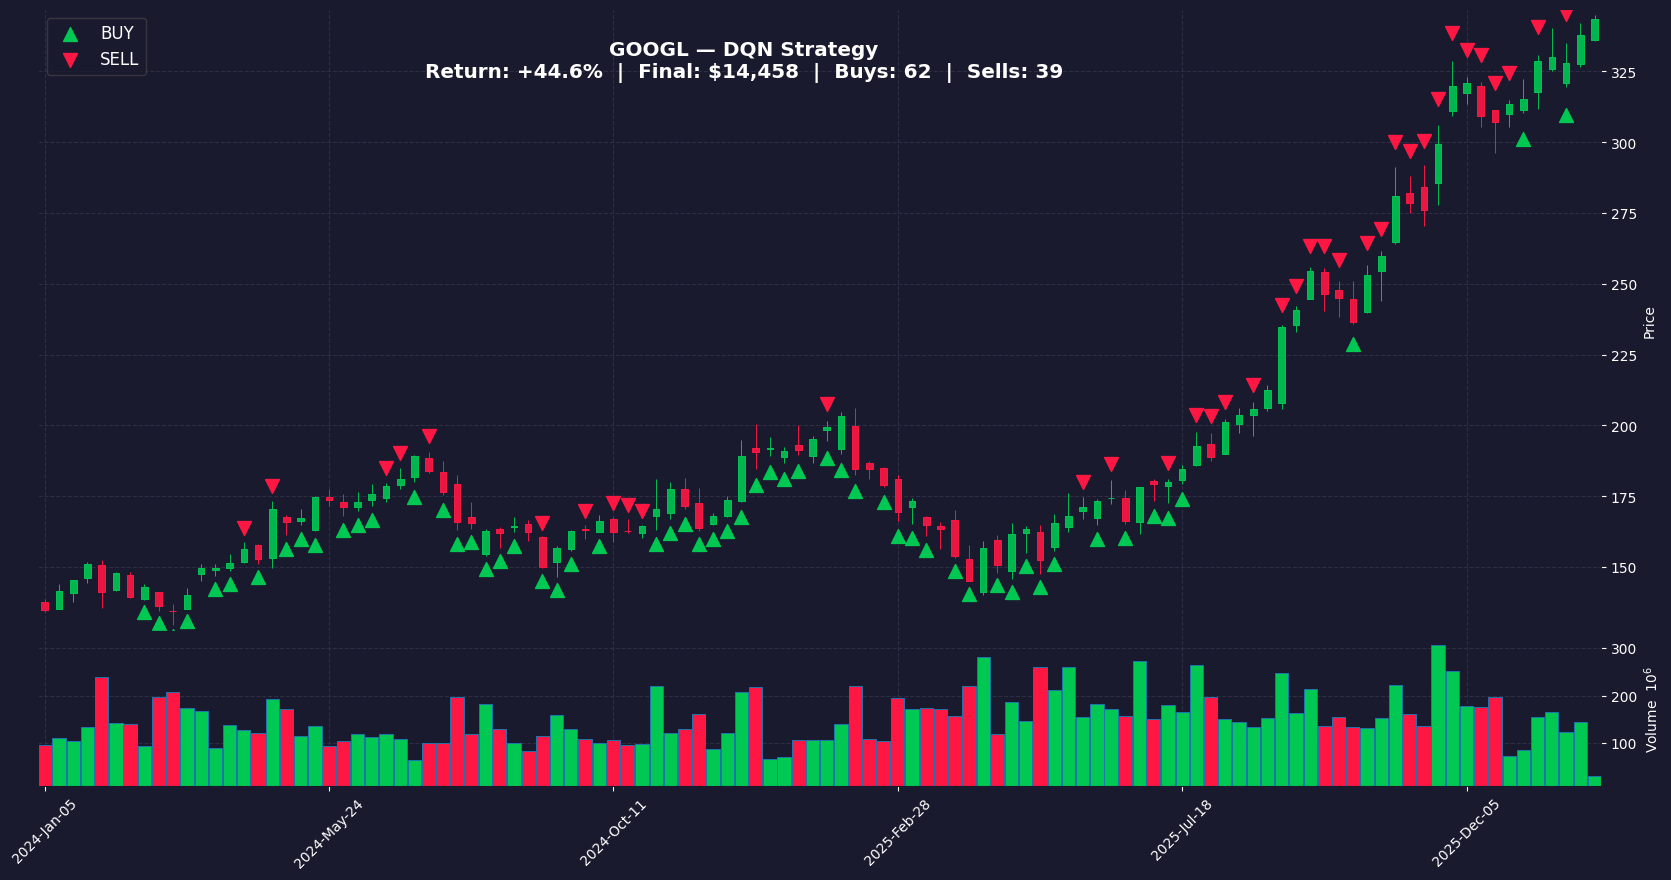

In [63]:
plot_ticker('GOOGL', method='DQN')

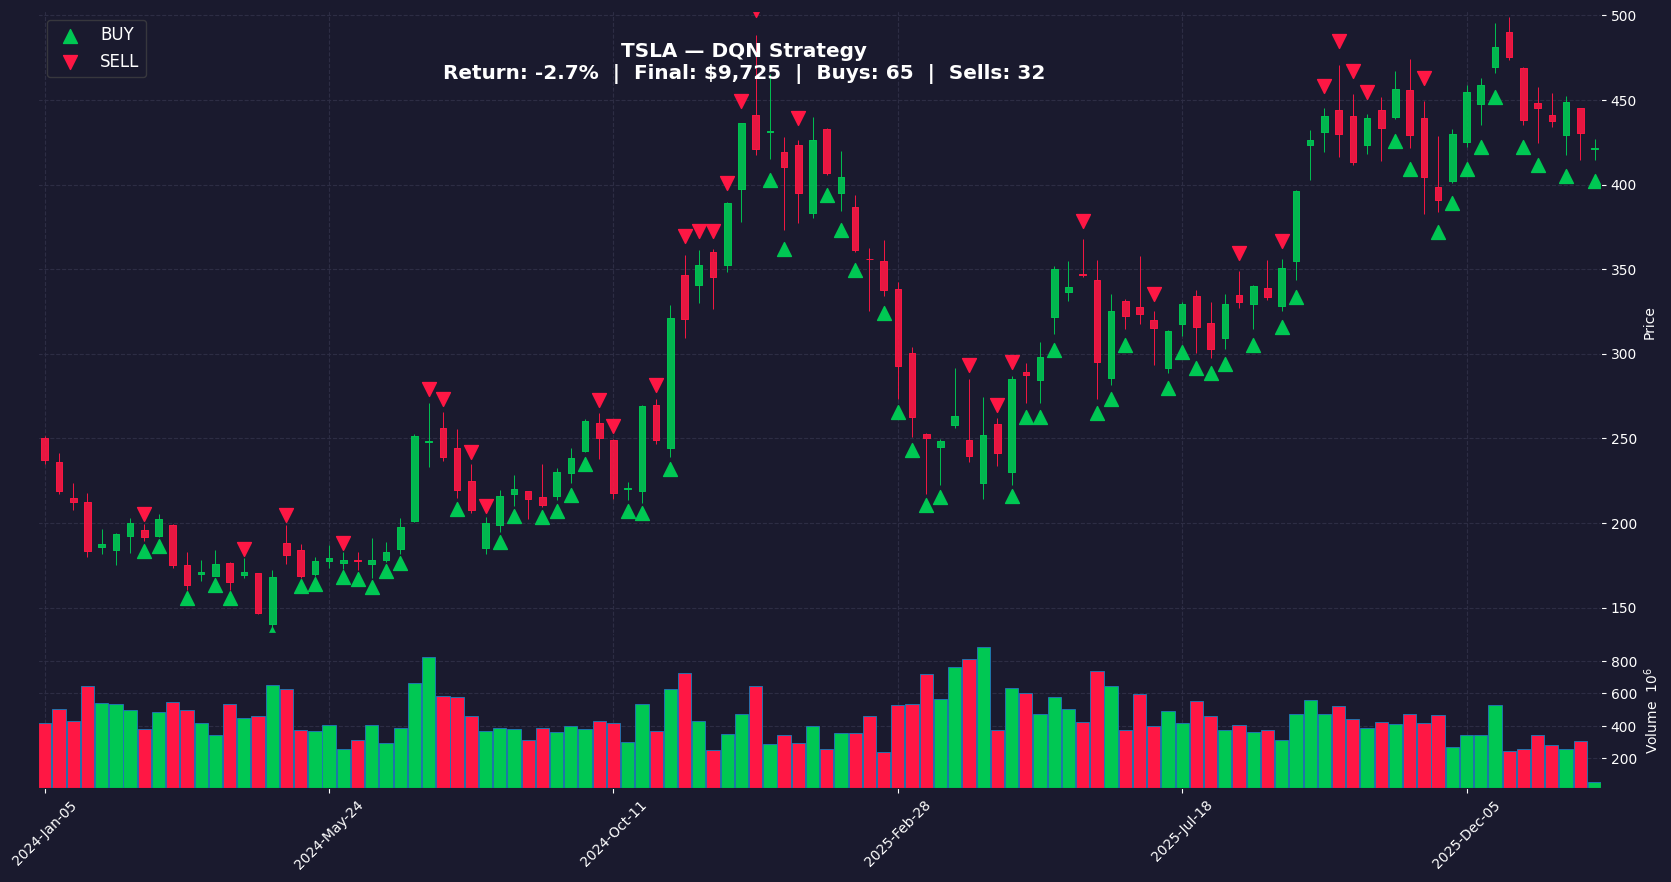

In [64]:
plot_ticker('TSLA', method='DQN')

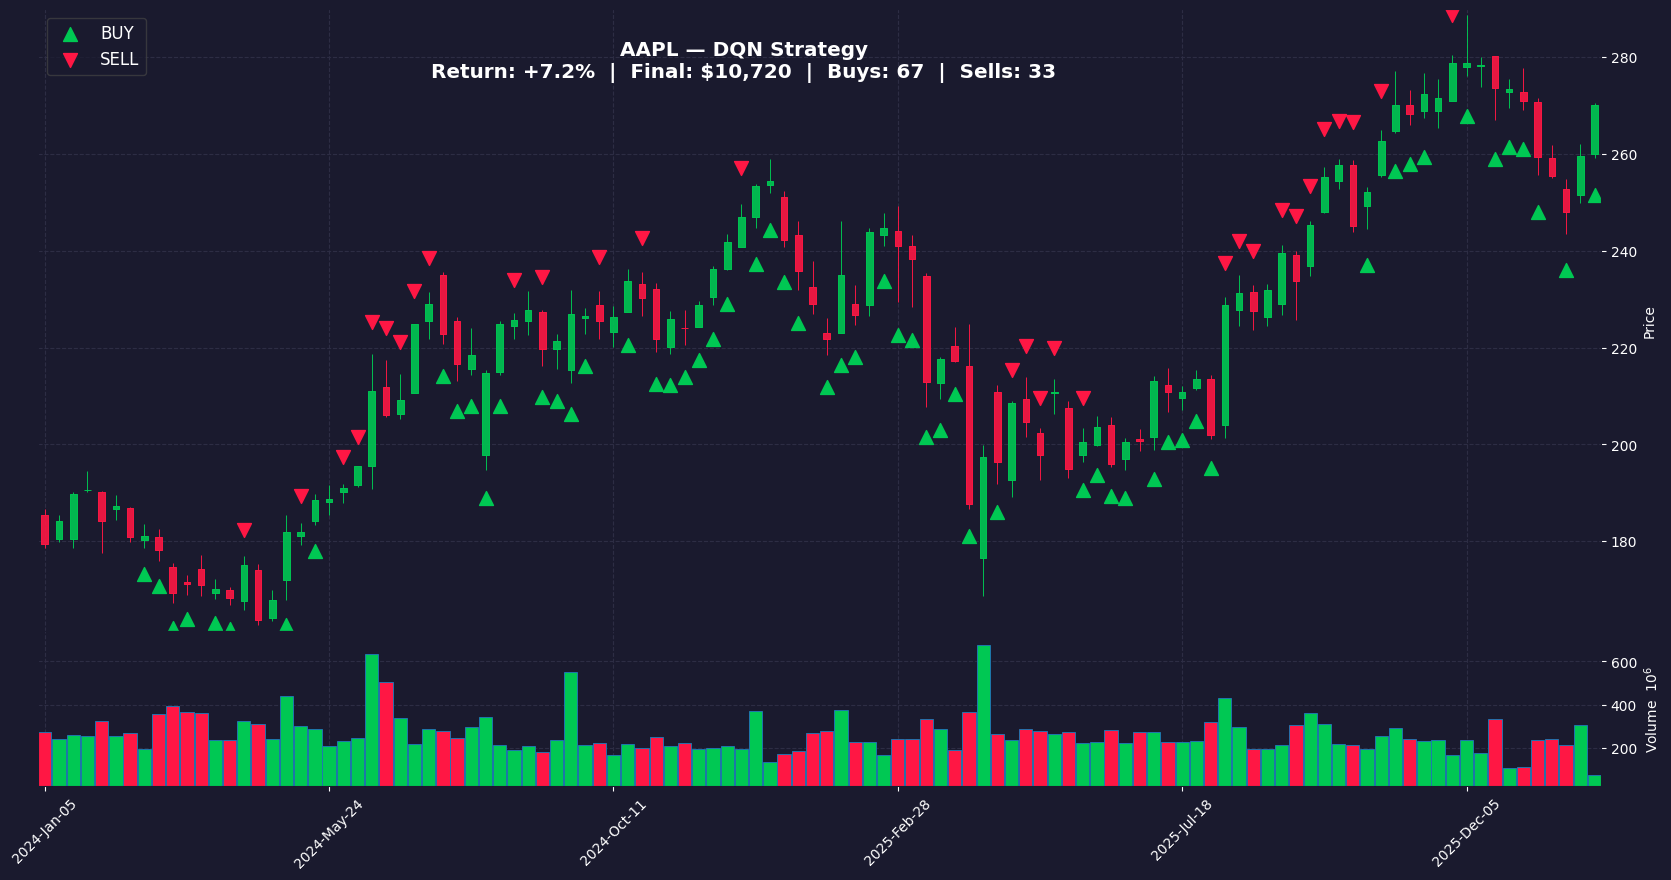

In [65]:
plot_ticker('AAPL', method='DQN')

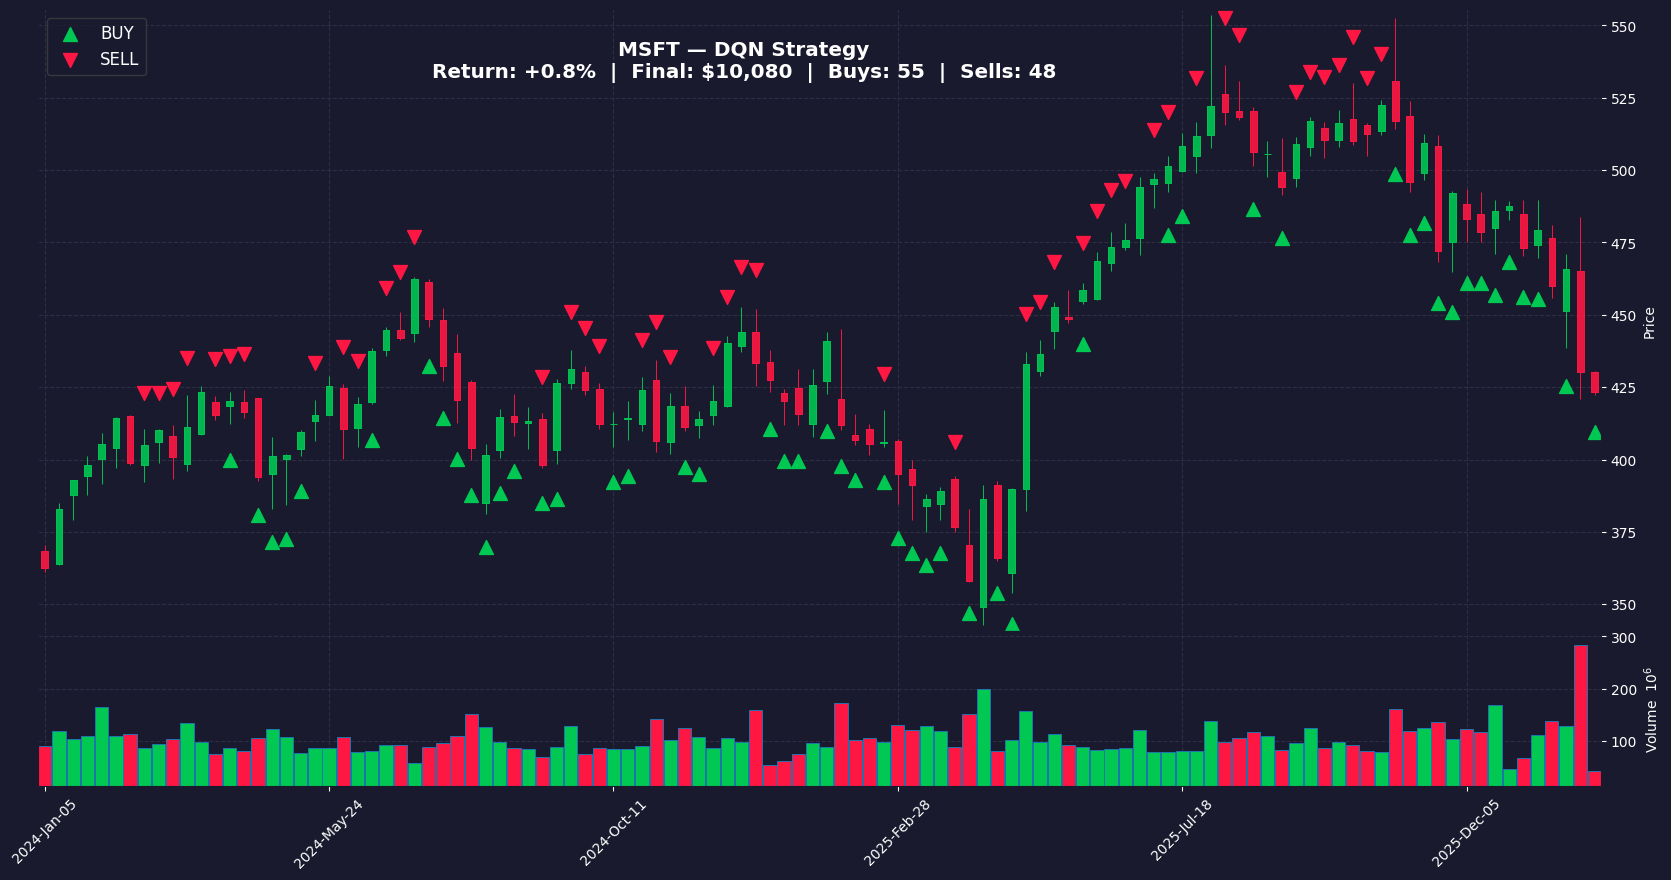

In [66]:
plot_ticker('MSFT', method='DQN')

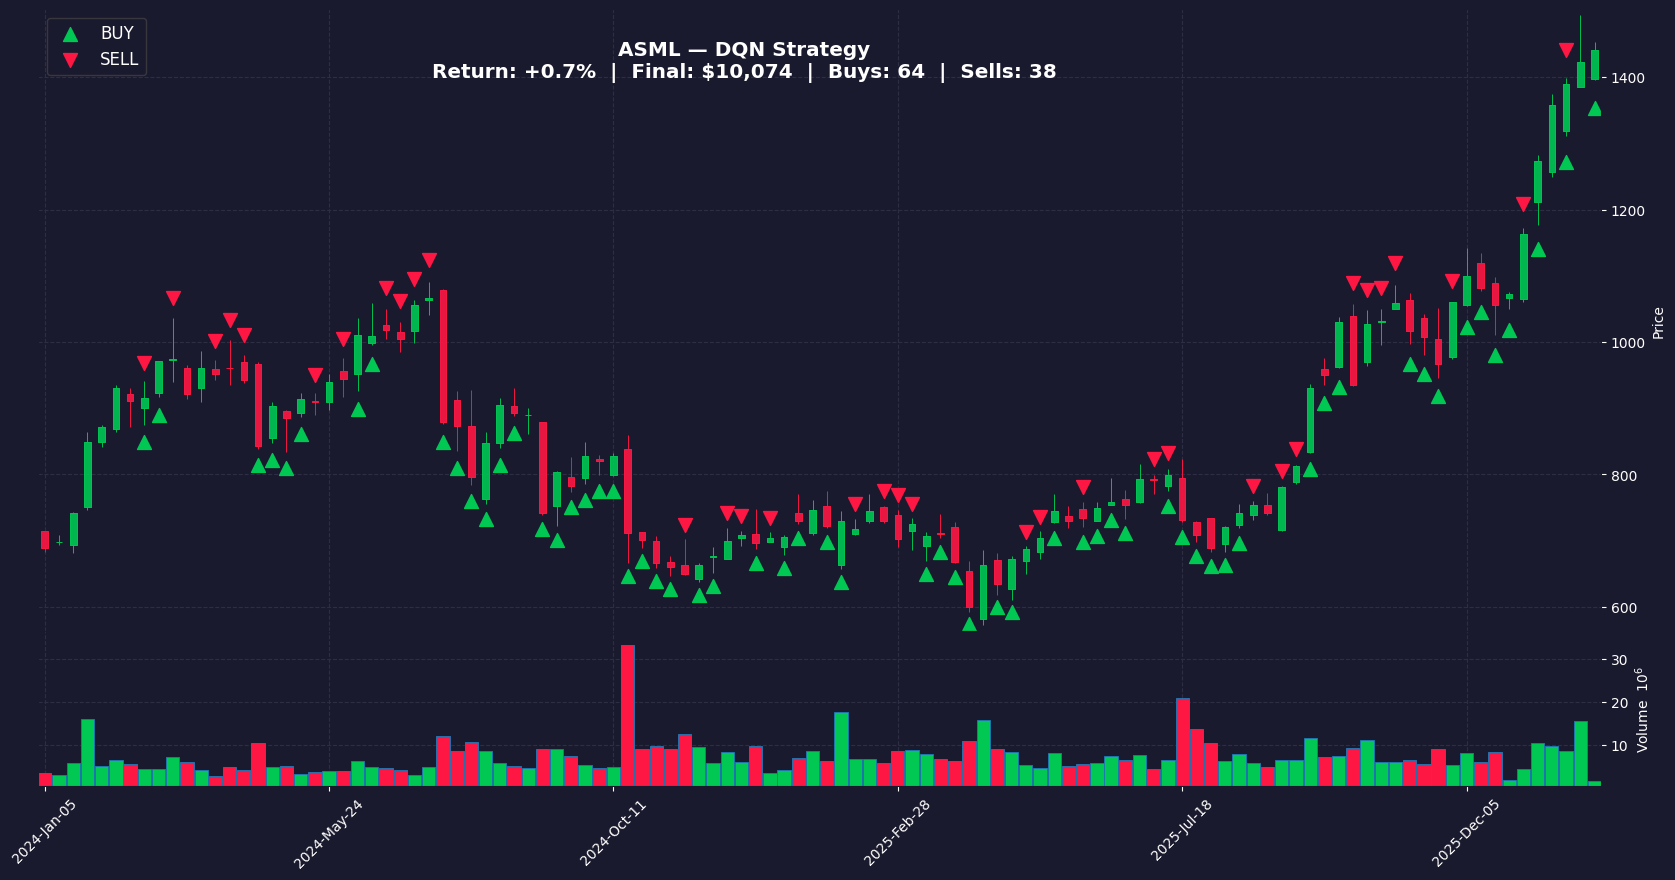

In [67]:
plot_ticker('ASML', method='DQN')

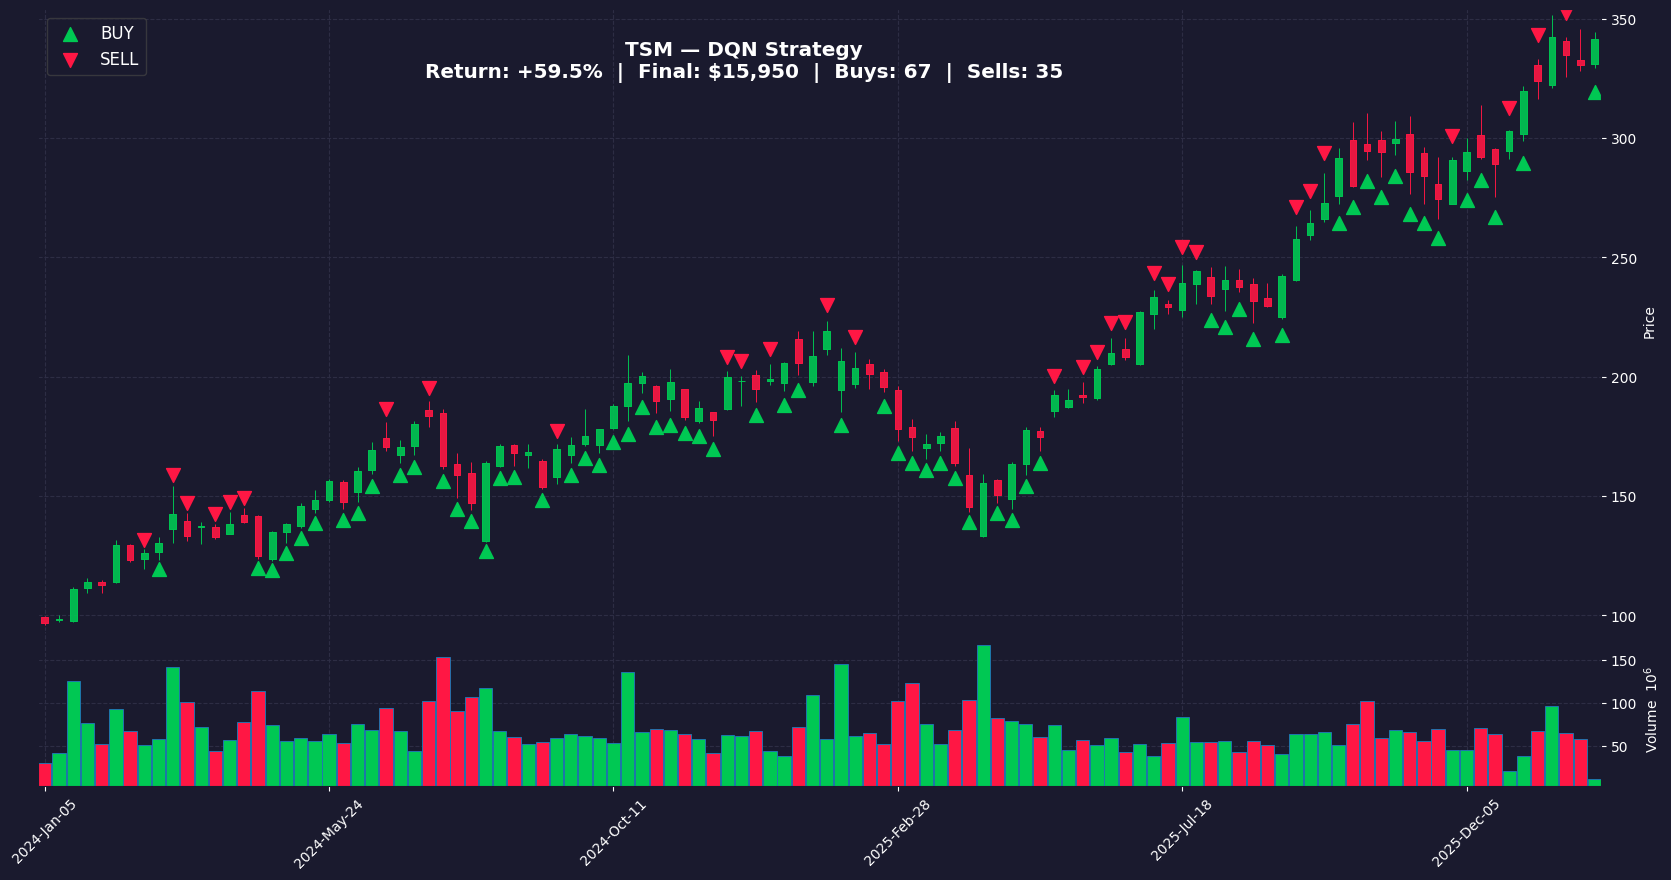

In [68]:
plot_ticker('TSM', method='DQN')